In [1]:
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"

import tensorflow as tf
import tf_keras as keras

I0000 00:00:1793014739.759293  192257 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793014739.813521  192257 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793014741.267772  192257 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [3]:
import tensorflow as tf

train = tf.keras.utils.image_dataset_from_directory(
    "../../data/classification/Train",
    image_size=(224, 224),
    batch_size=8,
    shuffle=True
)

val = tf.keras.utils.image_dataset_from_directory(
    "../../data/classification/Val",
    image_size=(224, 224),
    batch_size=8,
    shuffle=False
)

test = tf.keras.utils.image_dataset_from_directory(
    "../../data/classification/Test",
    image_size=(224, 224),
    batch_size=8,
    shuffle=False
)

Found 4218 files belonging to 4 classes.


I0000 00:00:1793014766.144981  192257 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 2193 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


Found 787 files belonging to 4 classes.
Found 789 files belonging to 4 classes.


In [ ]:
# def preprocess(images, labels):
#     images = tf.cast(images, tf.float32)
#     images = images / 127.5 - 1
#     return images, labels

# train = train.map(preprocess)
# val = val.map(preprocess)
# test = test.map(preprocess)

In [4]:


base_model = keras.applications.InceptionV3(
    weights="imagenet",
    include_top=False,
    input_shape=(299, 299, 3),
    pooling="avg"
)

base_model.trainable = True


In [5]:
for layer in base_model.layers[:-20]:
    layer.trainable = False

for layer in base_model.layers:
    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False



In [6]:
model = keras.Sequential([
    keras.layers.Input(shape=(224, 224, 3)),

    # Redimensionner les images
    keras.layers.Resizing(299, 299),

    # Prétraiter les pixels pour InceptionV3
    keras.layers.Lambda(
        keras.applications.inception_v3.preprocess_input
    ),

    # Extraire les caractéristiques
    base_model,

    # Réduire le surapprentissage
    keras.layers.Dropout(0.4),

    # Classifier les 4 catégories
    keras.layers.Dense(4, activation="softmax")
])

In [7]:
model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.00001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [8]:
# model.compile(
#     optimizer="adam",
#     loss="sparse_categorical_crossentropy",
#     metrics=["accuracy"]
# )

model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 resizing (Resizing)         (None, 299, 299, 3)       0         
                                                                 
 lambda (Lambda)             (None, 299, 299, 3)       0         
                                                                 
 inception_v3 (Functional)   (None, 2048)              21802784  
                                                                 
 dropout (Dropout)           (None, 2048)              0         
                                                                 
 dense (Dense)               (None, 4)                 8196      
                                                                 
Total params: 21810980 (83.20 MB)
Trainable params: 1499140 (5.72 MB)
Non-trainable params: 20311840 (77.48 MB)
_________________________________________________________________


In [10]:
callbacks = [
    keras.callbacks.ModelCheckpoint(
        "best_inceptionv3.keras",
        monitor="val_loss",
        save_best_only=True
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )
]

In [11]:
history = model.fit(
    train,
    validation_data=val,
    epochs=5,
    callbacks=callbacks
)

Epoch 1/5


I0000 00:00:1793014799.019583  192912 cuda_dnn.cc:461] Loaded cuDNN version 92700
W0000 00:00:1793014799.983472  192912 bfc_allocator.cc:311] Allocator (GPU_0_bfc) ran out of memory trying to allocate 2.00GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.
I0000 00:00:1793014803.107210  192914 service.cc:153] XLA service 0x4d9bc660 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793014803.107243  192914 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 3050 Laptop GPU, Compute Capability 8.6 (Driver: 13.4.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1793014803.113359  192914 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1793014803.178684  192914 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most

528/528 [==============================] - ETA: 0s - loss: 0.9548 - accuracy: 0.6105

W0000 00:00:1793014834.224066  192915 bfc_allocator.cc:311] Allocator (GPU_0_bfc) ran out of memory trying to allocate 2.04GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.


528/528 [==============================] - 47s 75ms/step - loss: 0.9548 - accuracy: 0.6105 - val_loss: 0.6601 - val_accuracy: 0.7840
Epoch 2/5
528/528 [==============================] - 33s 62ms/step - loss: 0.5563 - accuracy: 0.7994 - val_loss: 0.5039 - val_accuracy: 0.8297
Epoch 3/5
528/528 [==============================] - 33s 63ms/step - loss: 0.4283 - accuracy: 0.8468 - val_loss: 0.4351 - val_accuracy: 0.8450
Epoch 4/5
528/528 [==============================] - 33s 63ms/step - loss: 0.3664 - accuracy: 0.8732 - val_loss: 0.3894 - val_accuracy: 0.8564
Epoch 5/5
528/528 [==============================] - 33s 62ms/step - loss: 0.3226 - accuracy: 0.8886 - val_loss: 0.3565 - val_accuracy: 0.8640


98/99 [============================>.] - ETA: 0s

W0000 00:00:1793014994.060535  192906 bfc_allocator.cc:311] Allocator (GPU_0_bfc) ran out of memory trying to allocate 2.00GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.


99/99 [==============================] - 8s 77ms/step
              precision    recall  f1-score   support

      Glioma     0.9379    0.7784    0.8507       194
  Meningioma     0.8036    0.9247    0.8599       239
    No Tumor     0.9823    0.9098    0.9447       122
   Pituitary     0.9167    0.9402    0.9283       234

    accuracy                         0.8910       789
   macro avg     0.9101    0.8883    0.8959       789
weighted avg     0.8978    0.8910    0.8910       789



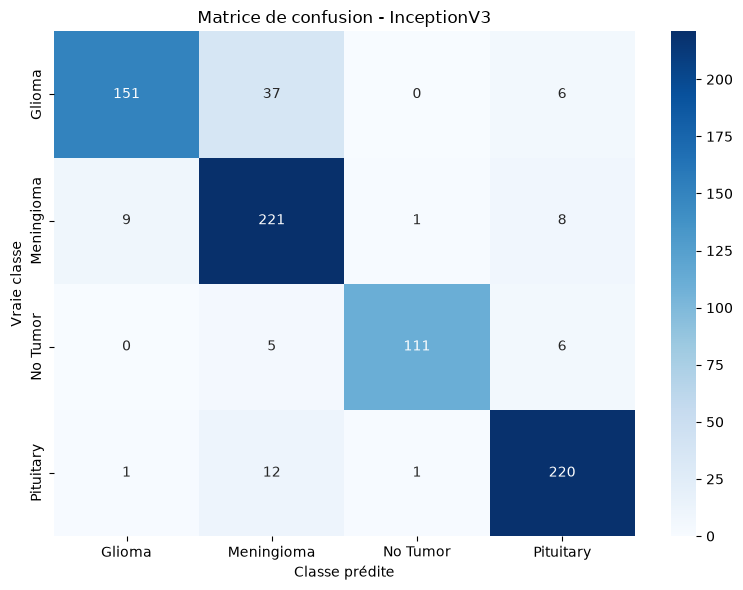

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import classification_report, confusion_matrix

# Les vraies classes
y_true = np.concatenate([
    labels.numpy() for images, labels in test
])

# Les prédictions du modèle
y_prob = model.predict(test)
y_pred = np.argmax(y_prob, axis=1)

# Les noms des classes
class_names = test.class_names

# Rapport détaillé
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))

# Matrice de confusion
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Classe prédite")
plt.ylabel("Vraie classe")
plt.title("Matrice de confusion - InceptionV3")
plt.tight_layout()
plt.show()

In [13]:

# Évaluer le modèle sur le jeu de test
test_loss, test_accuracy = model.evaluate(test)

print(f"Test loss : {test_loss:.4f}")
print(f"Test accuracy : {test_accuracy:.2%}")


99/99 [==============================] - 5s 46ms/step - loss: 0.3211 - accuracy: 0.8910
Test loss : 0.3211
Test accuracy : 89.10%


In [ ]:
model.save("../model/classification.keras")